In [2]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
DATA_DIR = Path("../home-credit-default-risk")

train = pd.read_csv(DATA_DIR / "application_train.csv")

print("Dataset shape:", train.shape)
display(train.head())

Dataset shape: (307511, 122)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [4]:
missing = pd.DataFrame({
    "missing_count": train.isnull().sum(),
    "missing_percent": train.isnull().mean().mul(100)
})

missing = missing[missing["missing_count"] > 0]
missing = missing.sort_values("missing_percent", ascending=False)

display(missing.head(20).round(2))

print(f"Columns with missing values: {len(missing)}")
print(f"Total missing cells: {train.isnull().sum().sum():,}")

,missing_count,missing_percent
COMMONAREA_MEDI,214865,69.87
COMMONAREA_MODE,214865,69.87
COMMONAREA_AVG,214865,69.87
NONLIVINGAPARTMENTS_MODE,213514,69.43
NONLIVINGAPARTMENTS_MEDI,213514,69.43
NONLIVINGAPARTMENTS_AVG,213514,69.43
FONDKAPREMONT_MODE,210295,68.39
LIVINGAPARTMENTS_AVG,210199,68.35
LIVINGAPARTMENTS_MEDI,210199,68.35
LIVINGAPARTMENTS_MODE,210199,68.35


Columns with missing values: 67
Total missing cells: 9,152,465


In [5]:
target_counts = train["TARGET"].value_counts()

print(f"Non-default cases: {target_counts[0]:,}")
print(f"Default cases:     {target_counts[1]:,}")
print(f"Default rate:      {train['TARGET'].mean():.2%}")

Non-default cases: 282,686
Default cases:     24,825
Default rate:      8.07%


In [6]:
# Compare default rates across selected numerical features
features = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "DAYS_BIRTH",
    "DAYS_EMPLOYED",
]

for feature in features:
    print(f"\n{feature}")
    print(
        train.groupby(
            pd.qcut(train[feature], q=5, duplicates="drop")
        )["TARGET"].mean().round(3)
    )


AMT_INCOME_TOTAL
AMT_INCOME_TOTAL
(25649.999, 99000.0]       0.082
(99000.0, 135000.0]        0.086
(135000.0, 162000.0]       0.087
(162000.0, 225000.0]       0.081
(225000.0, 117000000.0]    0.065
Name: TARGET, dtype: float64

AMT_CREDIT
AMT_CREDIT
(44999.999, 254700.0]    0.072
(254700.0, 432000.0]     0.092
(432000.0, 604152.0]     0.101
(604152.0, 900000.0]     0.079
(900000.0, 4050000.0]    0.061
Name: TARGET, dtype: float64

AMT_ANNUITY
AMT_ANNUITY
(1615.499, 14701.5]    0.069
(14701.5, 21865.5]     0.086
(21865.5, 28062.0]     0.088
(28062.0, 37516.5]     0.093
(37516.5, 258025.5]    0.067
Name: TARGET, dtype: float64

DAYS_BIRTH
DAYS_BIRTH
(-25229.001, -20474.0]    0.052
(-20474.0, -17220.0]      0.067
(-17220.0, -14416.0]      0.079
(-14416.0, -11694.0]      0.093
(-11694.0, -7489.0]       0.113
Name: TARGET, dtype: float64

DAYS_EMPLOYED
DAYS_EMPLOYED
(-17912.001, -3231.0]    0.054
(-3231.0, -1695.0]       0.077
(-1695.0, -822.0]        0.101
(-822.0, -144.0]         0.113


results show three useful patterns:
- Age: Younger customers have higher default rates in these groups.
- Employment: Shorter employment duration is associated with higher default rates, though the special value 365243 needs investigation.
- Income and loan amount: The relationship isn't consistently linear, so the model should capture nonlinear patterns.


### Feature engineering

In [7]:
# Convert negative day counts into years
train["AGE_YEARS"] = -train["DAYS_BIRTH"] / 365.25

# 365243 is a placeholder for missing employment duration
train["EMPLOYED_YEARS"] = (
    train["DAYS_EMPLOYED"]
    .replace(365243, np.nan)
    .abs() / 365.25
)

# Loan size relative to annual income
train["CREDIT_INCOME_RATIO"] = (
    train["AMT_CREDIT"] / train["AMT_INCOME_TOTAL"].replace(0, np.nan)
)

display(
    train[
        ["AGE_YEARS", "EMPLOYED_YEARS", "CREDIT_INCOME_RATIO", "TARGET"]
    ].describe().round(2)
)

/tmp/ipykernel_20717/1405935266.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train["AGE_YEARS"] = -train["DAYS_BIRTH"] / 365.25
/tmp/ipykernel_20717/1405935266.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train["EMPLOYED_YEARS"] = (
/tmp/ipykernel_20717/1405935266.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, u

,AGE_YEARS,EMPLOYED_YEARS,CREDIT_INCOME_RATIO,TARGET
count,307511.00,252137.00,307511.00,307511.00
mean,43.91,6.53,3.96,0.08
std,11.95,6.40,2.69,0.27
min,20.50,0.00,0.00,0.00
25%,33.98,2.10,2.02,0.00
50%,43.12,4.51,3.27,0.00
75%,53.89,8.69,5.16,0.00
max,69.07,49.04,84.74,1.00


main observations:
- Age: Average applicant age is about 44 years.
- Employment: Average recorded employment duration is 6.53 years. Only 252,137 applicants have valid employment durations because the placeholder was converted to missing.
- Credit-to-income ratio: The average is 3.96, meaning the credit amount is about 3.96 times annual income on average.
- Target: About 8% of applicants experienced payment difficulties, confirming that the dataset is imbalanced.

#### outliers and feature distributions

,count,mean,std,min,90%,95%,99%,max
AGE_YEARS,307511.0,43.91,11.95,20.5,60.73,63.53,66.86,69.07
EMPLOYED_YEARS,252137.0,6.53,6.40,0.0,14.60,19.96,31.04,49.04
CREDIT_INCOME_RATIO,307511.0,3.96,2.69,0.0,7.49,9.16,13.03,84.74


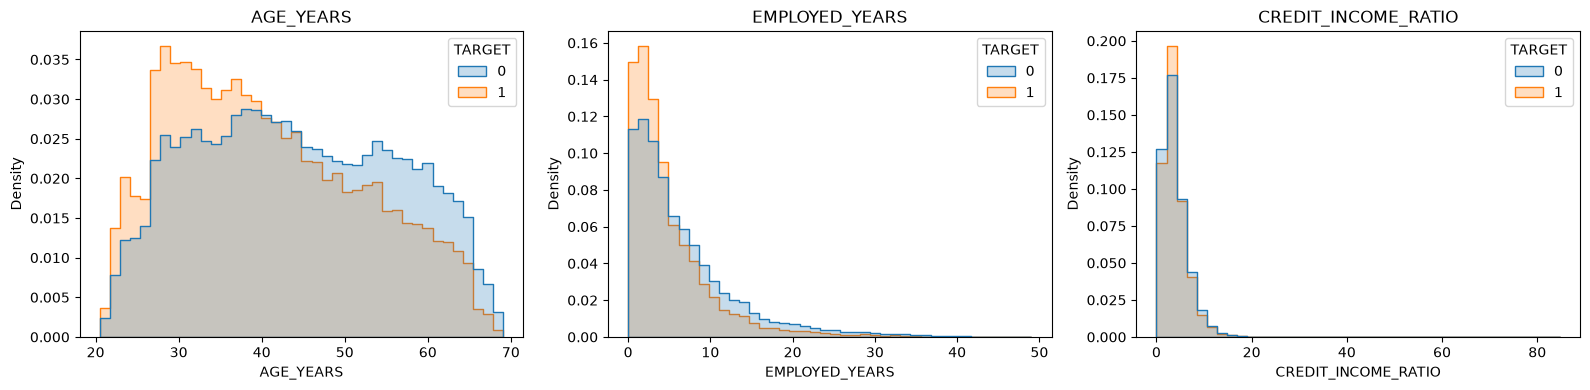

In [8]:
features = [
    "AGE_YEARS",
    "EMPLOYED_YEARS",
    "CREDIT_INCOME_RATIO"
]

display(train[features].describe(percentiles=[0.90, 0.95, 0.99]).T.round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, feature in zip(axes, features):
    sns.histplot(
        data=train,
        x=feature,
        hue="TARGET",
        bins=40,
        stat="density",
        common_norm=False,
        element="step",
        ax=ax
    )
    ax.set_title(feature)

plt.tight_layout()
plt.show()

EDA has revealed an important issue: CREDIT_INCOME_RATIO has extreme values, with a maximum of 84.74 compared with a median of 3.27. That means some applicants have credit amounts more than 84 times their annual income. These values may be genuine or data-quality issues, so we should investigate rather than delete them automatically.
- Age: Most applicants are between their mid-30s and early 60s.
- Employment: 99% of valid employment durations are at or below 31 years.
- Credit-to-income ratio: 99% are at or below 13.03, while the maximum is 84.74.
Next step: Inspect the extreme ratios

In [9]:
# Inspect applicants with the highest credit-to-income ratios
display(
    train.nlargest(10, "CREDIT_INCOME_RATIO")[
        [
            "SK_ID_CURR",
            "AMT_INCOME_TOTAL",
            "AMT_CREDIT",
            "CREDIT_INCOME_RATIO",
            "TARGET"
        ]
    ]
)

# Compare the ratio for applicants with and without payment difficulties
display(
    train.groupby("TARGET")["CREDIT_INCOME_RATIO"]
    .agg(["count", "mean", "median", "max"])
    .round(2)
)

,SK_ID_CURR,AMT_INCOME_TOTAL,AMT_CREDIT,CREDIT_INCOME_RATIO,TARGET
20727,124157,25650.0,2173500.0,84.736842,1
35791,141454,45000.0,2215224.0,49.227200,0
226137,361920,45000.0,1800000.0,40.000000,1
255247,395348,58500.0,2146500.0,36.692308,1
158077,283247,40500.0,1436850.0,35.477778,0
678,100784,54000.0,1885500.0,34.916667,1
205575,338291,36000.0,1223010.0,33.972500,1
103862,220543,54000.0,1800000.0,33.333333,0
165555,291918,27000.0,900000.0,33.333333,0
193574,324475,27900.0,916470.0,32.848387,0


,count,mean,median,max
TARGET,,,,
0,282686,3.96,3.27,49.23
1,24825,3.89,3.25,84.74


1. Extreme values exist: The highest credit-to-income ratio is 84.74. The applicant's income is ₦25,650 while the credit amount is ₦2,173,500. We should retain this applicant for now rather than automatically remove the record.
2. The ratio alone may not be a strong predictor: The average ratio is 3.96 for TARGET=0 and 3.89 for TARGET=1. The medians are also similar. We need to test predictive usefulness through modeling rather than judge by these summary statistics alone.
Next step: Prepare the data for modeling
We'll start with a simple baseline using only application_train.csv. We won't merge the other large datasets yet. First, we'll establish a reliable baseline, then improve it with feature engineering and additional data.


### DATA PREPARATION

In [10]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = train.drop(columns=["TARGET", "SK_ID_CURR"])
y = train["TARGET"]

# Identify numerical and categorical columns
numeric_cols = X.select_dtypes(include=["number"]).columns.tolist()
categorical_cols = X.select_dtypes(include=["object"]).columns.tolist()

print("Total features:", X.shape[1])
print("Numerical features:", len(numeric_cols))
print("Categorical features:", len(categorical_cols))

# Split before fitting any preprocessing steps
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining rows:", X_train.shape[0])
print("Validation rows:", X_valid.shape[0])
print("Training payment-difficulty rate:", round(y_train.mean(), 4))
print("Validation payment-difficulty rate:", round(y_valid.mean(), 4))

/tmp/ipykernel_20717/2277473622.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(include=["object"]).columns.tolist()


Total features: 123
Numerical features: 107
Categorical features: 16

Training rows: 246008
Validation rows: 61503
Training payment-difficulty rate: 0.0807
Validation payment-difficulty rate: 0.0807


Features: 123 before removing the customer ID, leaving 122 usable columns, including 107 numerical and 16 categorical features after the ID is removed.
Target rate: 8.07% in both sets, confirming that stratification worked.

### preprocessing pipeline

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# Numerical features: replace missing values with the median
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical features: fill missing values and encode categories
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the appropriate preprocessing to each feature type
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


Logistic Regression.

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, classification_report
from sklearn.pipeline import Pipeline

# Combine preprocessing and model training
baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train the model
baseline_model.fit(X_train, y_train)

# Predict probabilities on validation data
y_valid_proba = baseline_model.predict_proba(X_valid)[:, 1]

# Evaluate using ROC-AUC
auc = roc_auc_score(y_valid, y_valid_proba)

print(f"Validation ROC-AUC: {auc:.4f}")

/home/gamp/Desktop/adafolabi/Learn2earn/AI/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Validation ROC-AUC: 0.6339


LightGBM on the same 50,000-row sample and compare it with Logistic Regression's ROC-AUC of 0.6339.

In [13]:
import lightgbm as lgb
from sklearn.metrics import roc_auc_score
from sklearn.base import clone
from sklearn.pipeline import Pipeline

In [15]:
from sklearn.model_selection import train_test_split

X_small, _, y_small, _ = train_test_split(
    X_train,
    y_train,
    train_size=50000,
    random_state=42,
    stratify=y_train
)

print("Sample features:", X_small.shape)
print("Sample targets:", y_small.shape)

Sample features: (50000, 123)
Sample targets: (50000,)


In [16]:
# LightGBM handles missing values and categorical encoding through our pipeline
lgbm_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", lgb.LGBMClassifier(
        n_estimators=500,
        learning_rate=0.05,
        num_leaves=31,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    ))
])

# Train on the same 50,000 rows
lgbm_model.fit(X_small, y_small)

# Evaluate on the same validation set
lgbm_valid_proba = lgbm_model.predict_proba(X_valid)[:, 1]
lgbm_auc = roc_auc_score(y_valid, lgbm_valid_proba)

print(f"Logistic Regression ROC-AUC: 0.6339")
print(f"LightGBM ROC-AUC:           {lgbm_auc:.4f}")

Logistic Regression ROC-AUC: 0.6339
LightGBM ROC-AUC:           0.7368


LightGBM is better at distinguishing applicants who experience payment difficulties from those who do not. This is a promising result, though both models were trained on only 50,000 rows, and Logistic Regression had a convergence warning.

### Check for overfitting
Before improving the model, let's compare its performance on the training sample and validation set. Add this cell:

In [17]:
from sklearn.metrics import roc_auc_score

# Predictions on training and validation data
train_proba = lgbm_model.predict_proba(X_small)[:, 1]
valid_proba = lgbm_model.predict_proba(X_valid)[:, 1]

train_auc = roc_auc_score(y_small, train_proba)
valid_auc = roc_auc_score(y_valid, valid_proba)

print(f"Training ROC-AUC:   {train_auc:.4f}")
print(f"Validation ROC-AUC: {valid_auc:.4f}")
print(f"AUC gap:            {train_auc - valid_auc:.4f}")

Training ROC-AUC:   0.9616
Validation ROC-AUC: 0.7368
AUC gap:            0.2248


This confirms significant overfitting in our current LightGBM model.
The model performs extremely well on the 50,000 applicants it learned from but much worse on unseen applicants. A gap of 0.2248 is large, so we should reduce model complexity before proceeding.

Next step: Train a simpler LightGBM
Replace the previous LightGBM training cell with this version. It limits tree depth, reduces the number of leaves, and adds regularization.

In [18]:
lgbm_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", lgb.LGBMClassifier(
        n_estimators=500,
        learning_rate=0.03,
        num_leaves=15,
        max_depth=5,
        min_child_samples=100,
        reg_alpha=1.0,
        reg_lambda=5.0,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    ))
])

lgbm_model.fit(X_small, y_small)

train_proba = lgbm_model.predict_proba(X_small)[:, 1]
valid_proba = lgbm_model.predict_proba(X_valid)[:, 1]

train_auc = roc_auc_score(y_small, train_proba)
valid_auc = roc_auc_score(y_valid, valid_proba)

print(f"Training ROC-AUC:   {train_auc:.4f}")
print(f"Validation ROC-AUC: {valid_auc:.4f}")
print(f"AUC gap:            {train_auc - valid_auc:.4f}")

Training ROC-AUC:   0.8383
Validation ROC-AUC: 0.7513
AUC gap:            0.0870


The validation AUC improved by 0.0145, and the gap dropped substantially. This suggests the simpler model generalizes better, although we should still test it on a separate holdout set before making strong claims.

,feature,importance
29,numeric__EXT_SOURCE_3,507
28,numeric__EXT_SOURCE_2,409
27,numeric__EXT_SOURCE_1,364
9,numeric__DAYS_ID_PUBLISH,330
3,numeric__AMT_ANNUITY,304
4,numeric__AMT_GOODS_PRICE,279
106,numeric__CREDIT_INCOME_RATIO,261
8,numeric__DAYS_REGISTRATION,222
6,numeric__DAYS_BIRTH,219
105,numeric__EMPLOYED_YEARS,215


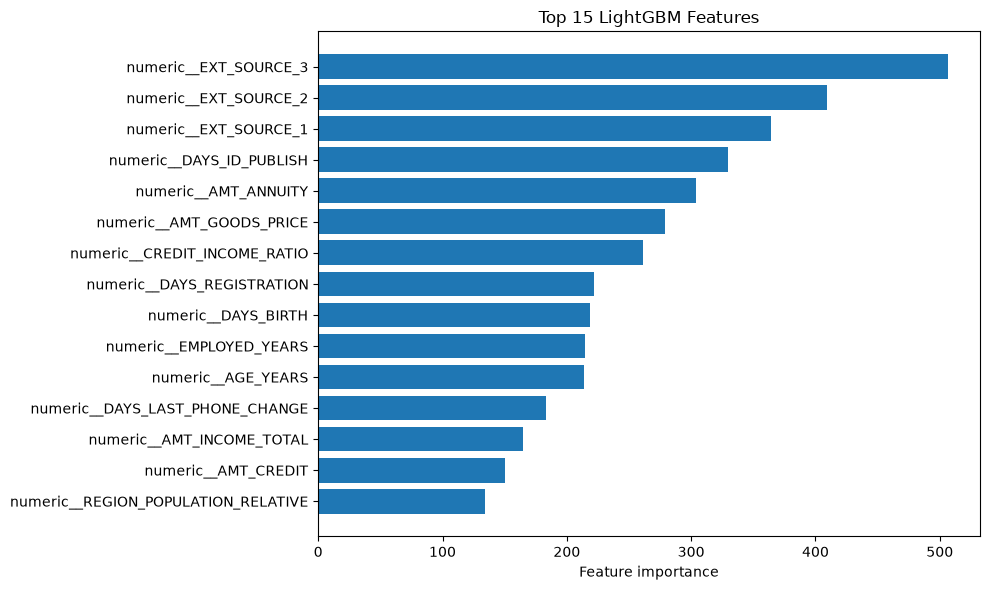

In [19]:
import pandas as pd
import matplotlib.pyplot as plt

# Get feature names after preprocessing
feature_names = lgbm_model.named_steps["preprocessor"].get_feature_names_out()

# Get LightGBM feature importance
importances = lgbm_model.named_steps["classifier"].feature_importances_

importance_df = (
    pd.DataFrame({
        "feature": feature_names,
        "importance": importances
    })
    .sort_values("importance", ascending=False)
)

display(importance_df.head(20))

# Plot the top 15 features
top_features = importance_df.head(15).sort_values("importance")

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.xlabel("Feature importance")
plt.title("Top 15 LightGBM Features")
plt.tight_layout()
plt.show()

SHAP summary plot to understand which features influence our LightGBM predictions most.

/home/gamp/Desktop/adafolabi/Learn2earn/AI/.venv/lib/python3.12/site-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


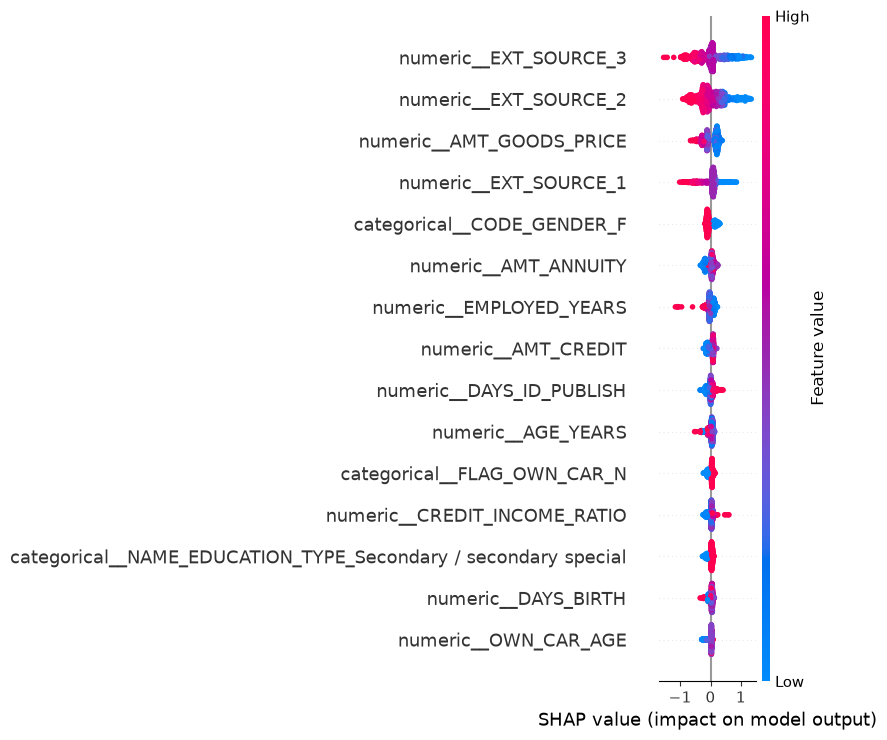

In [20]:
import shap
import matplotlib.pyplot as plt

# Explain a manageable sample of validation applicants
X_explain = X_valid.sample(n=1000, random_state=42)

# Transform features using the fitted preprocessing pipeline
X_explain_transformed = (
    lgbm_model.named_steps["preprocessor"]
    .transform(X_explain)
)

feature_names = (
    lgbm_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Explain the trained LightGBM model
classifier = lgbm_model.named_steps["classifier"]
explainer = shap.TreeExplainer(classifier)
shap_values = explainer.shap_values(X_explain_transformed)

# For binary classification, select the positive class if needed
if isinstance(shap_values, list):
    shap_values = shap_values[1]

shap.summary_plot(
    shap_values,
    X_explain_transformed,
    feature_names=feature_names,
    max_display=15
)

features near the top have greater overall influence. Each dot represents an applicant. SHAP values to the right push the prediction toward higher payment-difficulty risk; values to the left push it lower.

We're explaining 1,000 applicants rather than the entire validation set to keep computation manageable.


Explain one applicant.  
Let's select one validation applicant and identify which features pushed their predicted risk higher or lower.

In [21]:
# Select one validation applicant
customer_index = X_valid.index[0]
customer = X_valid.loc[[customer_index]]

# Get predicted probability of payment difficulties
risk_probability = lgbm_model.predict_proba(customer)[0, 1]

print("Customer ID:", train.loc[customer_index, "SK_ID_CURR"])
print(f"Predicted payment-difficulty probability: {risk_probability:.2%}")
print("Actual target:", y_valid.loc[customer_index])

Customer ID: 396899
Predicted payment-difficulty probability: 28.05%
Actual target: 0


customer's SHAP waterfall plot

/home/gamp/Desktop/adafolabi/Learn2earn/AI/.venv/lib/python3.12/site-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


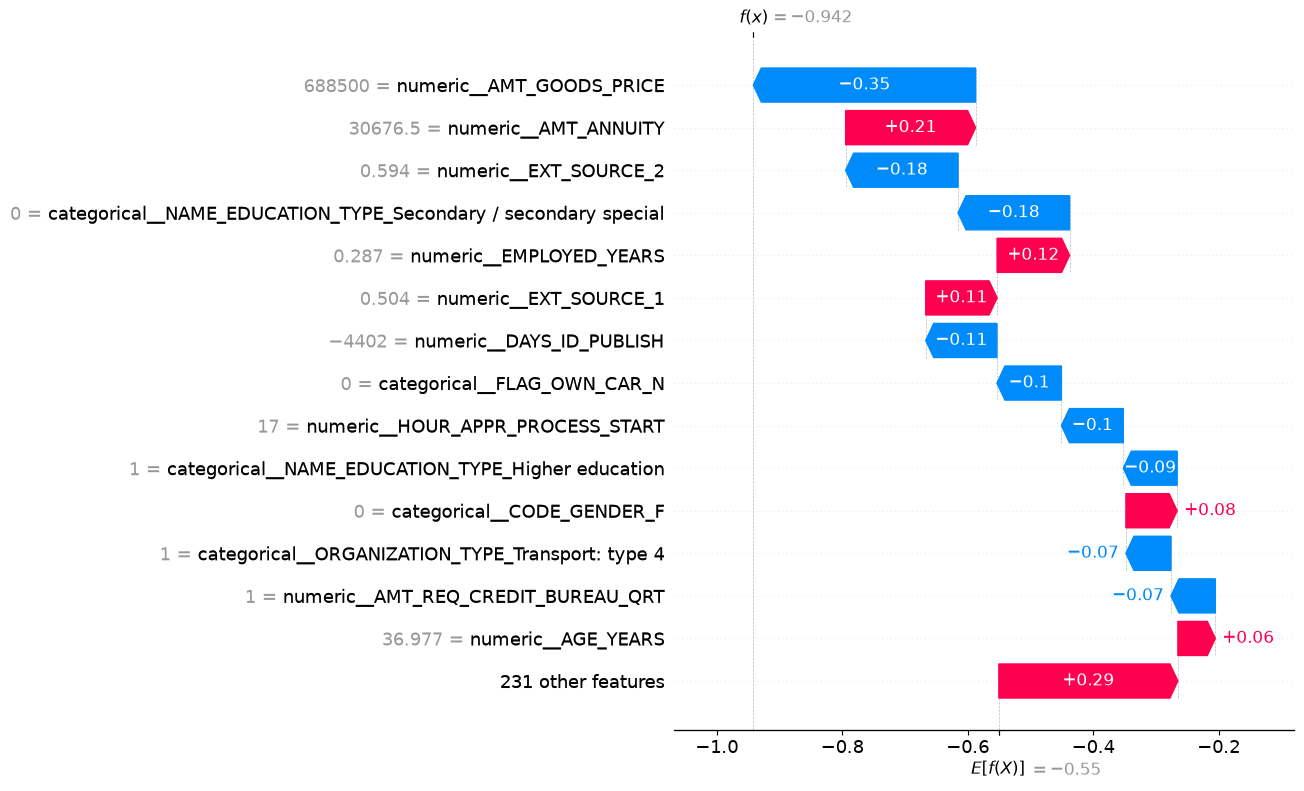

In [22]:
# Get the transformed features for this customer
customer_transformed = (
    lgbm_model.named_steps["preprocessor"]
    .transform(customer)
)

# Calculate SHAP values for this customer
customer_shap = explainer.shap_values(customer_transformed)

if isinstance(customer_shap, list):
    customer_shap = customer_shap[1]

# Build an explanation for the positive class
base_value = explainer.expected_value
if isinstance(base_value, (list, np.ndarray)):
    base_value = base_value[1]

explanation = shap.Explanation(
    values=customer_shap[0],
    base_values=base_value,
    data=customer_transformed.toarray()[0]
        if hasattr(customer_transformed, "toarray")
        else customer_transformed[0],
    feature_names=feature_names
)

shap.plots.waterfall(explanation, max_display=15)

already completed:
- Data exploration and missing-value analysis.
- Feature engineering.
- Train/validation split.
- Logistic Regression baseline: 0.6339 ROC-AUC.
- LightGBM model: 0.7513 validation ROC-AUC.
- Overfitting checks and feature importance.
- Global and individual SHAP explanations.

In [23]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Validation probabilities and predictions
valid_proba = lgbm_model.predict_proba(X_valid)[:, 1]
valid_pred = (valid_proba >= 0.5).astype(int)

print(f"ROC-AUC: {roc_auc_score(y_valid, valid_proba):.4f}")
print(f"Average Precision: {average_precision_score(y_valid, valid_proba):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_valid, valid_pred))

print("\nClassification Report:")
print(classification_report(y_valid, valid_pred, zero_division=0))

ROC-AUC: 0.7513
Average Precision: 0.2388

Confusion Matrix:
[[41170 15368]
 [ 1779  3186]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.73      0.83     56538
           1       0.17      0.64      0.27      4965

    accuracy                           0.72     61503
   macro avg       0.57      0.68      0.55     61503
weighted avg       0.90      0.72      0.78     61503



our model has ROC-AUC 0.7513 and recall 0.64 for applicants with payment difficulties. That means it identifies about 64% of the positive cases at the current 0.5 threshold, but precision is only 17%, so many flagged applicants are false positives. This is why we evaluate more than accuracy.

### Save the trained model

In [24]:
from pathlib import Path
import joblib

MODEL_DIR = Path("../results/model")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

model_path = MODEL_DIR / "lightgbm_credit_model.joblib"
joblib.dump(lgbm_model, model_path)

print("Model saved to:", model_path.resolve())

Model saved to: /home/gamp/Desktop/adafolabi/Learn2earn/AI/credit-scoring/results/model/lightgbm_credit_model.joblib
